# Analyzing haplotypes

Nearby variants on the same haplotype (in *cis*) can have a combined effect that differs from the effect of each variant alone. This tutorial uses AlphaGenome 2 to compare the predicted effect of a multi-variant haplotype with the effects of its individual variants.

`dna_model.predict_variant` takes one `genome.Variant` per call. To evaluate nearby variants together on the same haplotype, combine them into a single multi-base `genome.Variant` that spans all of them.

Key activities:
- Check condition support in liver (`UBERON:0002107`) via `dna_model.supported_conditions()`.
- Construct a multi-variant `genome.Variant` spanning chr5:1295113:G>A and chr5:1295135:G>A at the *TERT* promoter.
- Predict observed `RNA_SEQ` and `ATAC` tracks for the combined haplotype and each single variant.
- Compare REF, individual single-variant ALT tracks, and ALT_Combined with `plot_components.OverlaidTracks`.

## Set up

In [1]:
# @title Install AlphaGenome

# @markdown Run this cell to install AlphaGenome.
from IPython.display import clear_output
! pip install alphagenome
clear_output()

In [2]:
# @title Imports
from alphagenome import colab_utils
from alphagenome.data import gene_annotation
from alphagenome.data import genome
from alphagenome.data import transcript as transcript_utils
from alphagenome.io import fasta
from alphagenome.models.v2 import dna_client
from alphagenome.visualization import plot_components
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['savefig.facecolor'] = 'white'
plt.rcParams['savefig.transparent'] = False

Store your API key in Colab Secrets for persistent access across sessions (see [Installation](https://www.alphagenomedocs.com/installation.html#add-api-key-to-secrets)), then initialize the client and check which liver (`UBERON:0002107`) outputs are observed:

In [3]:
dna_model = dna_client.create(colab_utils.get_api_key())

condition = 'UBERON:0002107'  # Liver.
dna_model.supported_conditions().set_index('condition').loc[
    condition, ['biosample_name', 'rna_seq', 'atac']
]

,UBERON:0002107
biosample_name,liver
rna_seq,observed
atac,observed


Load GENCODE v46 annotations and build a `TranscriptExtractor` for MANE Select protein-coding transcripts:

In [4]:
gtf = pd.read_feather(
    'https://storage.googleapis.com/alphagenome/reference/gencode/'
    'hg38/gencode.v46.annotation.gtf.gz.feather'
)
gtf_mane_protein = gene_annotation.filter_to_mane_select_transcript(
    gene_annotation.filter_protein_coding(gtf)
)
transcript_extractor = transcript_utils.TranscriptExtractor(gtf_mane_protein)

## Build a combined haplotype `Variant`

Define a helper that extracts the hg38 reference sequence spanning all variants, writes each variant's reference and alternate base into a REF and an ALT copy of that sequence, and returns one multi-site `genome.Variant` plus the individual variants. The helper supports single-base substitutions only:

In [5]:
FASTA_PATH = (
    'https://storage.googleapis.com/alphagenome/reference/'
    'gencode/hg38/GRCh38.p13.genome.fa'
)


def create_haplotype(mutations: list[genome.Variant]) -> dict:
  """Builds a multi-variant genome.Variant spanning [min_pos, max_pos]."""
  if not mutations:
    raise ValueError('Mutation list is empty.')

  chroms = {m.chromosome for m in mutations}
  if len(chroms) > 1:
    raise ValueError(f'Multiple chromosomes detected: {chroms}.')

  target_chr = next(iter(chroms))
  positions = [m.position for m in mutations]
  min_pos, max_pos = min(positions), max(positions)
  if (max_pos - min_pos) > 1_000_000:
    raise ValueError(f'Range too large: {max_pos - min_pos} bp. Max 1MB allowed.')

  extractor = fasta.FastaExtractor(FASTA_PATH)
  span_interval = genome.Interval(
      chromosome=target_chr, start=min_pos - 1, end=max_pos
  )
  raw_hg38_seq = extractor.extract(span_interval).upper()

  ref_list = list(raw_hg38_seq)
  alt_list = list(raw_hg38_seq)
  individual_variants = {}

  for mut in mutations:
    rel_index = mut.position - min_pos
    ref_list[rel_index] = mut.reference_bases.upper()
    alt_list[rel_index] = mut.alternate_bases.upper()
    individual_variants[mut.position] = mut

  return {
      'combined_variant': genome.Variant(
          chromosome=target_chr,
          position=min_pos,
          reference_bases=''.join(ref_list),
          alternate_bases=''.join(alt_list),
      ),
      'individual_variants': individual_variants,
  }

Construct a haplotype carrying the two recurrent *TERT* promoter mutations C228T (chr5:1295113:G>A) and C250T (chr5:1295135:G>A):

In [6]:
mutation_data = [
    genome.Variant(
        chromosome='chr5',
        position=1295113,
        reference_bases='G',
        alternate_bases='A',
    ),
    genome.Variant(
        chromosome='chr5',
        position=1295135,
        reference_bases='G',
        alternate_bases='A',
    ),
]

haplotype = create_haplotype(mutation_data)
print('Combined variant:', haplotype['combined_variant'])
print('Individual variants:', haplotype['individual_variants'])

Combined variant: chr5:1295113:GGGGGCTGGGCCGGGGACCCGGG>AGGGGCTGGGCCGGGGACCCGGA
Individual variants: {1295113: Variant(chromosome='chr5', position=1295113, reference_bases='G', alternate_bases='A', name=''), 1295135: Variant(chromosome='chr5', position=1295135, reference_bases='G', alternate_bases='A', name='')}


## Predict combined and individual variants

Center a 1 Mb window (`dna_client.SEQUENCE_LENGTH_1MB`) on the combined variant and predict `RNA_SEQ` and `ATAC` in liver for both the combined haplotype and each single variant:

In [7]:
interval = haplotype['combined_variant'].reference_interval.resize(
    dna_client.SEQUENCE_LENGTH_1MB
)

prediction_params = {
    'interval': interval,
    'requested_outputs': [
        dna_client.OutputType.RNA_SEQ,
        dna_client.OutputType.ATAC,
    ],
    'condition': condition,
}

all_predictions = {}
all_predictions['combined'] = dna_model.predict_variant(
    variant=haplotype['combined_variant'], **prediction_params
)
for pos, var_obj in haplotype['individual_variants'].items():
  all_predictions[pos] = dna_model.predict_variant(
      variant=var_obj, **prediction_params
  )

## Visualize haplotype predictions

Keep observed tracks (`filter_to_observed`), select the negative strand for `RNA_SEQ` (*TERT* is on the minus strand), and overlay REF, each single-variant ALT prediction, and ALT_Combined in a 5 kb window around the *TERT* promoter:

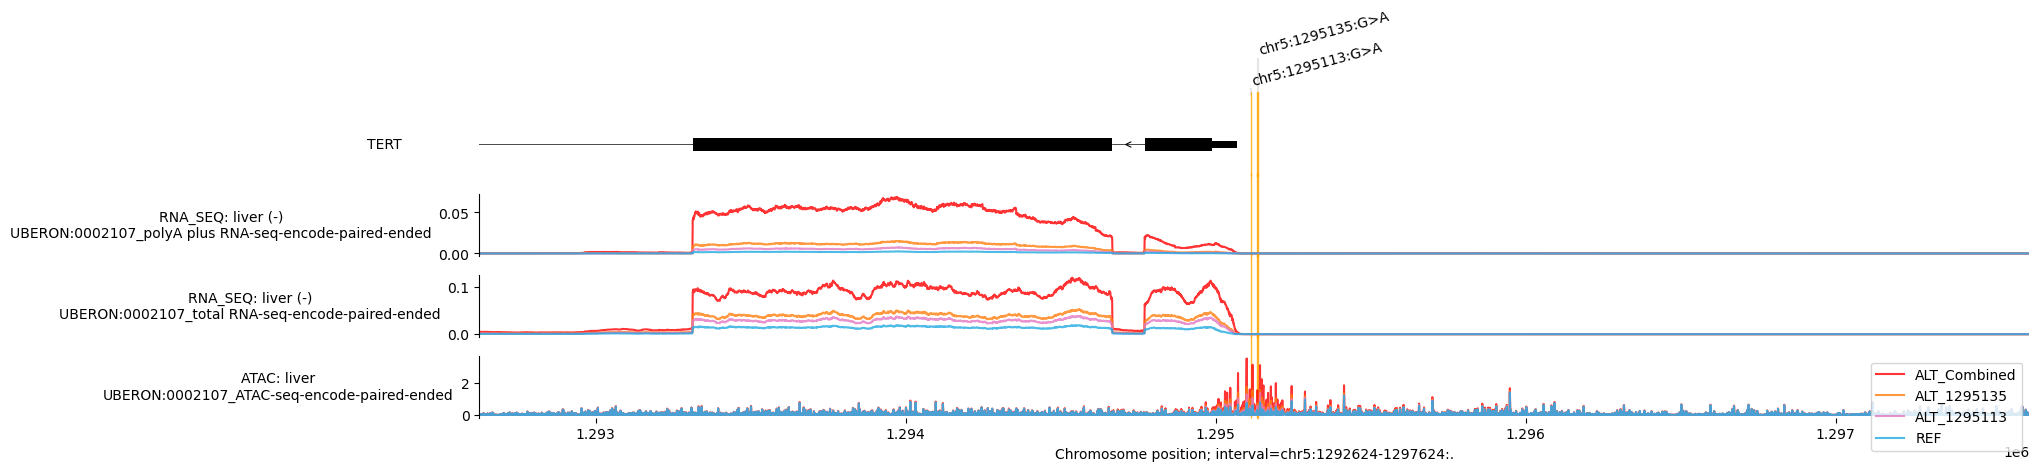

In [7]:
REF_COLOR = '#22AAE1'
COMBINED_COLOR = 'red'
palette = ['#e377c2', '#ff7f0e', '#2ca02c', '#9467bd']

tdata_rna = {}
tdata_atac = {}
colors = {}
annotations = []

obs_combined_ref = all_predictions['combined'].reference.filter_to_observed()
obs_combined_alt = all_predictions['combined'].alternate.filter_to_observed()

tdata_rna['REF'] = obs_combined_ref.rna_seq.filter_to_negative_strand()
tdata_atac['REF'] = obs_combined_ref.atac
colors['REF'] = REF_COLOR

tdata_rna['ALT_Combined'] = obs_combined_alt.rna_seq.filter_to_negative_strand()
tdata_atac['ALT_Combined'] = obs_combined_alt.atac
colors['ALT_Combined'] = COMBINED_COLOR

for i, (pos, var_obj) in enumerate(haplotype['individual_variants'].items()):
  obs_alt = all_predictions[pos].alternate.filter_to_observed()
  track_key = f'ALT_{pos}'
  tdata_rna[track_key] = obs_alt.rna_seq.filter_to_negative_strand()
  tdata_atac[track_key] = obs_alt.atac
  colors[track_key] = palette[i % len(palette)]
  annotations.append(plot_components.VariantAnnotation([var_obj], alpha=0.8))

transcripts = transcript_extractor.extract(interval)
_ = plot_components.plot(
    [
        plot_components.TranscriptAnnotation(transcripts),
        plot_components.OverlaidTracks(
            tdata=tdata_rna,
            colors=colors,
            ylabel_template='RNA_SEQ: {biosample_name} ({strand})\n{name}',
            legend_loc=None,
        ),
        plot_components.OverlaidTracks(
            tdata=tdata_atac,
            colors=colors,
            ylabel_template='ATAC: {biosample_name}\n{name}',
        ),
    ],
    interval=interval.resize(5000),
    annotations=annotations,
)
plt.show()

Comparing ALT_Combined against the individual single-variant predictions (ALT_1295113 and ALT_1295135) at the *TERT* promoter shows that AlphaGenome 2 predicts larger increases in local ATAC-seq accessibility and negative-strand RNA-seq coverage when both G>A substitutions occur together on the same haplotype than for either variant alone.